# YouTube Shorts Virality — EDA

**Question:** What makes a video go viral, and can we predict it early?

Data comes from the `shorts-data` repo (cloned next to this notebook). It has three parts:

| File | One row per | Contents |
|---|---|---|
| `data/channels.csv` | channel | title, creation date, subscribers, total views/videos |
| `data/videos.csv` | video | publish time, channel, title, description, duration, tags |
| `data/observations/*.csv` | video × snapshot | views, likes, comments at a point in time (roughly hourly) |

Run `git pull` inside `shorts-data` to get the newest snapshots before rerunning.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

# Find the folder that holds both cloned repos by walking up from wherever Jupyter was started,
# so this works on any machine as long as shorts-data sits next to this repo.
WORKSPACE = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shorts-data").is_dir()), None)
assert WORKSPACE is not None, f"Can't find shorts-data above {Path.cwd()} — clone it next to this repo"
DATA_DIR = WORKSPACE / "shorts-data" / "data"
PROJECT_DIR = WORKSPACE / "erdos2026fallproject"


## Load the data

In [2]:
channels = pd.read_csv(DATA_DIR / "channels.csv")
videos = pd.read_csv(DATA_DIR / "videos.csv")
for df, cols in [(channels, ["first_seen_at", "channel_created_at"]), (videos, ["first_seen_at", "published_at"])]:
    for col in cols:
        df[col] = pd.to_datetime(df[col], format="ISO8601", utc=True)

obs_files = sorted((DATA_DIR / "observations").glob("*.csv"))
observations = pd.concat((pd.read_csv(f) for f in obs_files), ignore_index=True)
observations["observed_at"] = pd.to_datetime(observations["observed_at"], format="ISO8601")

# Keep only US videos. Country is the channel's self-reported country (blank for many channels),
# so a video counts as US if its channel lists US.
countries = pd.read_csv(DATA_DIR / "channel_countries.csv")
us_channels = countries.loc[countries["channel_country"] == "US", "channel_id"]
n_videos_all = len(videos)
channels = channels[channels["channel_id"].isin(us_channels)]
videos = videos[videos["channel_id"].isin(us_channels)]
observations = observations[observations["video_id"].isin(videos["video_id"])]
print(f"kept {len(videos)} of {n_videos_all} videos from US channels")

print(f"channels:     {channels.shape}")
print(f"videos:       {videos.shape}")
print(f"observations: {observations.shape} from {len(obs_files)} snapshot files")
print(f"snapshots span {observations['observed_at'].min()} → {observations['observed_at'].max()}")


kept 1671 of 15668 videos from US channels
channels:     (940, 7)
videos:       (1671, 10)
observations: (108373, 6) from 228 snapshot files
snapshots span 2026-10-12 15:37:59.683152+00:00 → 2026-10-22 04:53:42.912419+00:00


In [3]:
channels.head()

,channel_id,first_seen_at,channel_title,channel_created_at,total_channel_views,subscriber_count,total_channel_videos
6,UCD4CupPMCP09s7oKyh4hyKA,2026-10-12 15:37:58.074627+00:00,Hercai Español,2020-01-29 06:54:55.888075+00:00,642585966,753000,7022
16,UCMm_V8YjmnZRhToXIqDYDuw,2026-10-12 15:37:58.074627+00:00,New England Patriots,2015-07-15 13:32:11+00:00,250528378,420000,10960
23,UC4MmGkfgigvN2CHrrH4DmDA,2026-10-12 15:37:58.074627+00:00,GOLDCRAFT STUDIOS,2023-08-23 12:20:10.989003+00:00,1881233431,11500000,199
24,UCENFLM4yBesR4ZzNhcJ86nw,2026-10-12 15:37:58.074627+00:00,Myst Editz,2025-12-22 18:06:24.664734+00:00,240540524,134000,233
45,UC7MmTlAULSkoByGbxYINARQ,2026-10-12 15:37:58.074627+00:00,FurtherEdit,2018-07-14 09:19:28+00:00,609969996,740000,230


In [4]:
videos.head()

,video_id,first_seen_at,published_at,channel_id,channel_title,title,description,duration,duration_seconds,tags
7,rqdvHIojVkM,2026-10-12 15:37:58.074627+00:00,2026-10-12 15:00:34+00:00,UCD4CupPMCP09s7oKyh4hyKA,Hercai Español,¡Reyyan abofeteó a Yaren!😲| Hercai #shorts,"Reyyan es la nieta de la familia Sadoglu, una ...",PT1M47S,107,"[""atv series"", ""Ver Ak\u0131n Ak\u0131n\u00f6z..."
22,HU0g35zypqE,2026-10-12 15:37:58.074627+00:00,2026-10-12 14:36:45+00:00,UCZPqCw7WAW844M3MVIbL4rA,正义格温,#Spider-Man #Gwen #Shorts #Spider-Gwen,NaN,PT49S,49,[]
31,hpiTSjic13M,2026-10-12 15:37:58.074627+00:00,2026-10-12 14:30:26+00:00,UCMm_V8YjmnZRhToXIqDYDuw,New England Patriots,"DeMario ""Pop had 2 tuds"" Douglas 👌 #patriots #...",NaN,PT29S,29,[]
35,no9nMjKGsDI,2026-10-12 15:37:58.074627+00:00,2026-10-12 14:20:09+00:00,UCaN9720mbtCGefgjo5Qkr0A,Bears Now by Chat Sports,"Ian Rapoport: ""All Signs Point"" Toward Caleb W...",NaN,PT56S,56,[]
62,Fc6khC8Xha4,2026-10-12 15:37:58.074627+00:00,2026-10-12 13:30:31+00:00,UC7MmTlAULSkoByGbxYINARQ,FurtherEdit,Name: Grey’s Anatomy | She Chose Freedom.🎬🎬 #m...,🎬 Original Edit — Crafted with Precision\n\nCu...,PT1M58S,118,"[""#shorts"", ""#edit"", ""#movie""]"


In [5]:
observations.head()

,video_id,observed_at,age_hours,view_count,like_count,comment_count
7,rqdvHIojVkM,2026-10-12 15:37:59.683152+00:00,0.624,227.0,9.0,1.0
22,HU0g35zypqE,2026-10-12 15:37:59.683152+00:00,1.021,57327.0,1175.0,1.0
31,hpiTSjic13M,2026-10-12 15:37:59.683152+00:00,1.126,4480.0,350.0,11.0
35,no9nMjKGsDI,2026-10-12 15:37:59.683152+00:00,1.297,4786.0,511.0,95.0
62,Fc6khC8Xha4,2026-10-12 15:37:59.850397+00:00,2.125,11167.0,932.0,10.0


## Data quality: types, missing values, duplicates

In [6]:
for name, df in [("channels", channels), ("videos", videos), ("observations", observations)]:
    print(f"--- {name} ---")
    print(df.dtypes.to_string())
    missing = df.isna().mean().mul(100).round(1)
    missing = missing[missing > 0]
    print()
    print("% missing:" if len(missing) else "no missing values")
    if len(missing):
        print(missing.to_string())
    print()


--- channels ---
channel_id                           object
first_seen_at           datetime64[ns, UTC]
channel_title                        object
channel_created_at      datetime64[ns, UTC]
total_channel_views                   int64
subscriber_count                      int64
total_channel_videos                  int64

no missing values

--- videos ---
video_id                         object
first_seen_at       datetime64[ns, UTC]
published_at        datetime64[ns, UTC]
channel_id                       object
channel_title                    object
title                            object
description                      object
duration                         object
duration_seconds                  int64
tags                             object

% missing:
description    39.0

--- observations ---
video_id                      object
observed_at      datetime64[ns, UTC]
age_hours                    float64
view_count                   float64
like_count                   float64
c

In [7]:
print("duplicate channel_ids:", channels["channel_id"].duplicated().sum())
print("duplicate video_ids:  ", videos["video_id"].duplicated().sum())
print("duplicate (video, snapshot) rows:", observations.duplicated(["video_id", "observed_at"]).sum())
print("observed videos missing from videos.csv:", (~observations["video_id"].isin(videos["video_id"])).sum())


duplicate channel_ids: 0
duplicate video_ids:   0
duplicate (video, snapshot) rows: 0
observed videos missing from videos.csv: 0


## One row per video: latest snapshot

Each video is observed many times. For a first look, keep each video's **most recent** observation and join on video and channel metadata.

In [8]:
latest = (
    observations.sort_values("observed_at")
    .groupby("video_id").tail(1)
    .merge(videos, on="video_id", how="left")
    .merge(channels.drop(columns=["channel_title", "first_seen_at"]), on="channel_id", how="left")
)
n_obs = observations.groupby("video_id").size().rename("n_observations")
latest = latest.merge(n_obs, on="video_id")
print(latest.shape)
latest[["view_count", "like_count", "comment_count", "age_hours", "duration_seconds",
        "subscriber_count", "n_observations"]].describe().T


(1670, 20)


,count,mean,std,min,25%,50%,75%,max
view_count,1670.0,3.857062e+05,1.121017e+06,281.000,28752.00000,80191.500,2.597958e+05,1.779190e+07
like_count,1569.0,7.597363e+03,2.298950e+04,3.000,549.00000,1664.000,5.624000e+03,5.091910e+05
comment_count,1652.0,1.513311e+02,5.189142e+02,0.000,4.00000,22.000,1.022500e+02,1.242700e+04
age_hours,1670.0,6.532780e+01,2.400125e+01,0.886,56.82675,79.386,7.988075e+01,7.999500e+01
duration_seconds,1670.0,5.114192e+01,3.624196e+01,4.000,26.00000,42.000,6.100000e+01,1.800000e+02
subscriber_count,1670.0,2.177927e+06,4.929780e+06,14.000,60700.00000,224000.000,1.497500e+06,3.870000e+07
n_observations,1670.0,6.489401e+01,2.401016e+01,1.000,56.25000,79.000,8.000000e+01,8.200000e+01


## First look at the distributions

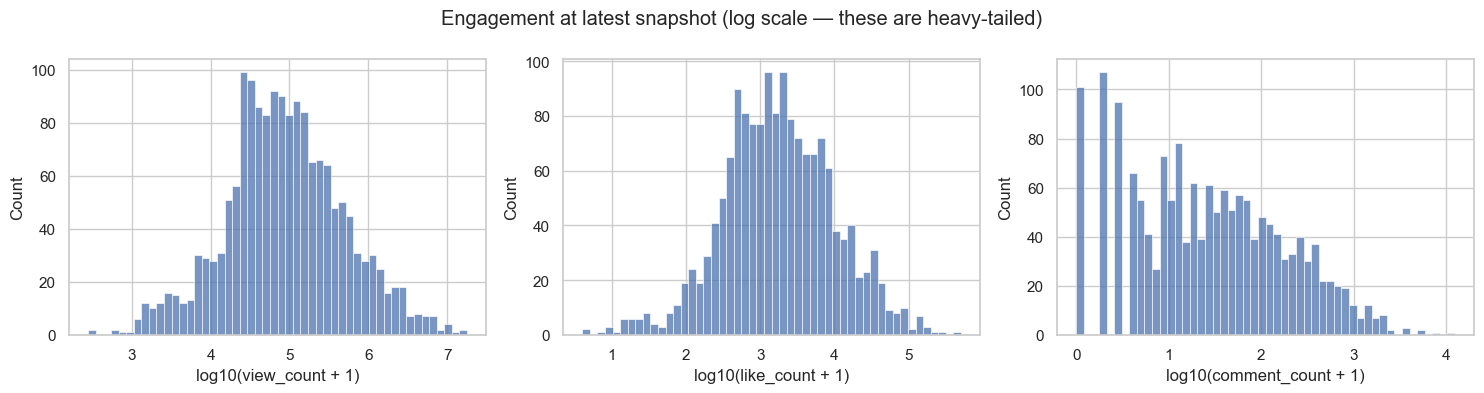

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["view_count", "like_count", "comment_count"]):
    sns.histplot(np.log10(latest[col].dropna() + 1), bins=50, ax=ax)
    ax.set_xlabel(f"log10({col} + 1)")
fig.suptitle("Engagement at latest snapshot (log scale — these are heavy-tailed)")
plt.tight_layout()


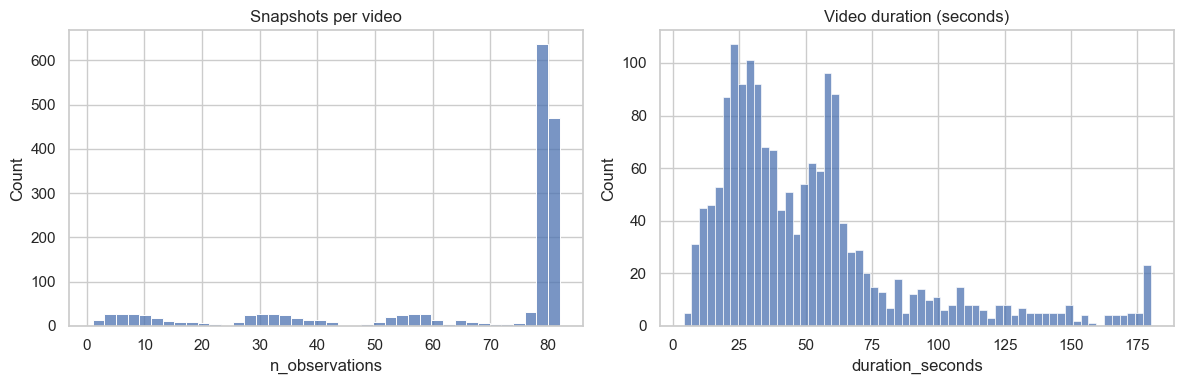

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(latest["n_observations"], bins=40, ax=axes[0])
axes[0].set_title("Snapshots per video")
sns.histplot(latest["duration_seconds"].dropna(), bins=60, ax=axes[1])
axes[1].set_title("Video duration (seconds)")
plt.tight_layout()


## View trajectories

How views grow with video age matters for predicting virality *early*. Plot a random sample of videos.

Text(0.5, 1.0, 'View trajectories for 30 sampled Shorts')

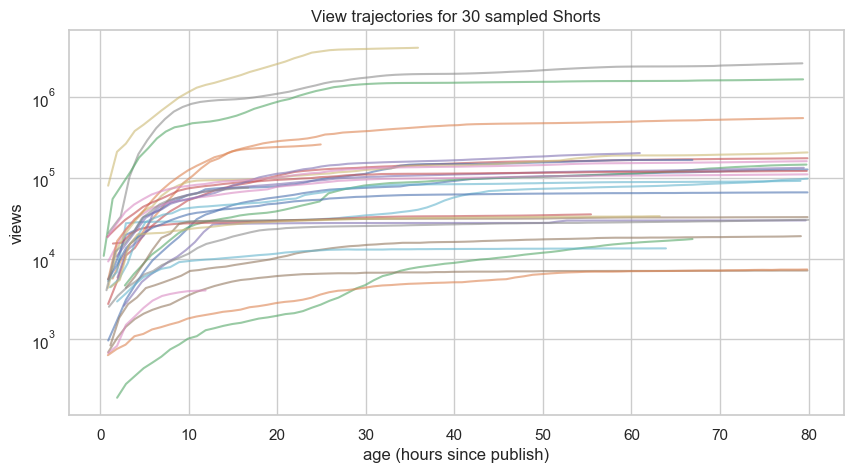

In [11]:
sample_ids = latest.query("n_observations >= 10")["video_id"].sample(30, random_state=0)
fig, ax = plt.subplots(figsize=(10, 5))
for vid, g in observations[observations["video_id"].isin(sample_ids)].groupby("video_id"):
    g = g.sort_values("age_hours")
    ax.plot(g["age_hours"], g["view_count"], alpha=0.6)
ax.set_yscale("log")
ax.set_xlabel("age (hours since publish)")
ax.set_ylabel("views")
ax.set_title("View trajectories for 30 sampled Shorts")


# Part 2: EDA toward the virality question

The sections below build a **one-row-per-video modeling table**: what we know about a video in its first few hours, plus the outcome we want to predict (its views at `TARGET_HOURS`). Then they explore that table along the lines of the checkpoint guide: distributions, missingness, relationships, outliers and lag structure.

Key plots are also saved to `results/eda/`.

In [12]:
import json
import re
from scipy import stats
from statsmodels.tsa.stattools import acf

TARGET_HOURS = 48      # outcome window; switch to 72 once enough videos have aged that far
TARGET_TOL = 2         # accept the snapshot closest to TARGET_HOURS if within ± this many hours
EARLY_HOURS = [1, 3, 6]
EARLY_TOL = 0.75
VIRAL_QUANTILE = 0.90  # "viral" = top 10%

RESULTS_DIR = PROJECT_DIR / "results" / "eda"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(RESULTS_DIR / f"{name}.png", dpi=120, bbox_inches="tight")

def stats_at(hours, tol):
    # Each video's snapshot closest to `hours` of age, if one exists within `tol` hours.
    o = observations.assign(dist=(observations["age_hours"] - hours).abs()).query("dist <= @tol")
    o = o.sort_values("dist").groupby("video_id").head(1).set_index("video_id")
    return o[["view_count", "like_count", "comment_count"]].add_suffix(f"_{hours}h")

max_age = observations.groupby("video_id")["age_hours"].max()
for h in [6, 24, 48, 72]:
    print(f"videos observed to >= {h}h: {(max_age >= h).sum()}")


videos observed to >= 6h: 1621
videos observed to >= 24h: 1491
videos observed to >= 48h: 1316
videos observed to >= 72h: 1150


## Build the modeling table

Features use only information available in a video's first few hours, or known at upload time, so they're fair to use for *early* prediction. The target columns (`*_{TARGET_HOURS}h`, `viral`, `viral_rel`) must never be used as features.

Two candidate labels:
- `viral`: views at `TARGET_HOURS` in the top 10% of this cohort.
- `viral_rel`: views relative to the channel's average views per video in the top 10%. This asks whether the video beat its own channel's usual performance.

In [13]:
df = (
    videos.set_index("video_id")
    .join([stats_at(h, EARLY_TOL) for h in EARLY_HOURS])
    .join(stats_at(TARGET_HOURS, TARGET_TOL), how="inner")
    .reset_index()
    .merge(channels.drop(columns=["channel_title", "first_seen_at"]), on="channel_id", how="left")
)
target = f"view_count_{TARGET_HOURS}h"

# Upload-time features
df["pub_hour_utc"] = df["published_at"].dt.hour
df["pub_dow"] = df["published_at"].dt.day_name().str[:3]
df["title_len"] = df["title"].fillna("").str.len()
df["n_hashtags"] = df["title"].fillna("").str.count("#") + df["description"].fillna("").str.count("#")
df["n_tags"] = df["tags"].fillna("[]").apply(lambda s: len(json.loads(s)))
df["has_description"] = df["description"].notna()
df["ascii_title"] = df["title"].fillna("").apply(str.isascii)  # rough proxy for English vs non-English

# Channel features (channel stats are as of first sighting, so known early)
df["channel_age_days"] = (df["published_at"] - df["channel_created_at"]).dt.days
df["channel_avg_views"] = df["total_channel_views"] / df["total_channel_videos"].clip(lower=1)

# Early-engagement features
df["likes_hidden"] = df["like_count_6h"].isna() & df["view_count_6h"].notna()
df["like_rate_6h"] = df["like_count_6h"] / df["view_count_6h"].replace(0, np.nan)
df["comment_rate_6h"] = df["comment_count_6h"] / df["view_count_6h"].replace(0, np.nan)
df["growth_1h_to_6h"] = df["view_count_6h"] / df["view_count_1h"].replace(0, np.nan)

# Labels
df["viral"] = df[target] >= df[target].quantile(VIRAL_QUANTILE)
df["rel_views"] = df[target] / df["channel_avg_views"].replace(0, np.nan)
df["viral_rel"] = df["rel_views"] >= df["rel_views"].quantile(VIRAL_QUANTILE)

print(f"{len(df)} videos with a {TARGET_HOURS}h outcome")
print(f"viral threshold: {df[target].quantile(VIRAL_QUANTILE):,.0f} views (median {df[target].median():,.0f})")


1321 videos with a 48h outcome
viral threshold: 779,085 views (median 86,008)


## Missingness

How many values are missing in each column of the modeling table, and what percent of rows that is.

In [14]:
feature_cols = ["view_count_1h", "view_count_3h", "view_count_6h", "like_count_6h", "comment_count_6h",
                "description", "subscriber_count", "duration_seconds", "title_len"]

missing = pd.DataFrame({
    "missing": df[feature_cols].isna().sum(),
    "percent": df[feature_cols].isna().mean().mul(100).round(1),
}).sort_values("missing", ascending=False)

print(f"{len(df)} videos in the modeling table")
missing

1321 videos in the modeling table


,missing,percent
description,527,39.9
view_count_1h,443,33.5
like_count_6h,89,6.7
comment_count_6h,25,1.9
view_count_3h,17,1.3
view_count_6h,8,0.6
subscriber_count,0,0.0
duration_seconds,0,0.0
title_len,0,0.0


## Box plots: outcome by group

Log scale throughout, since views span several orders of magnitude. Publish hour is in **UTC**. Creators are worldwide, so it isn't their local time.

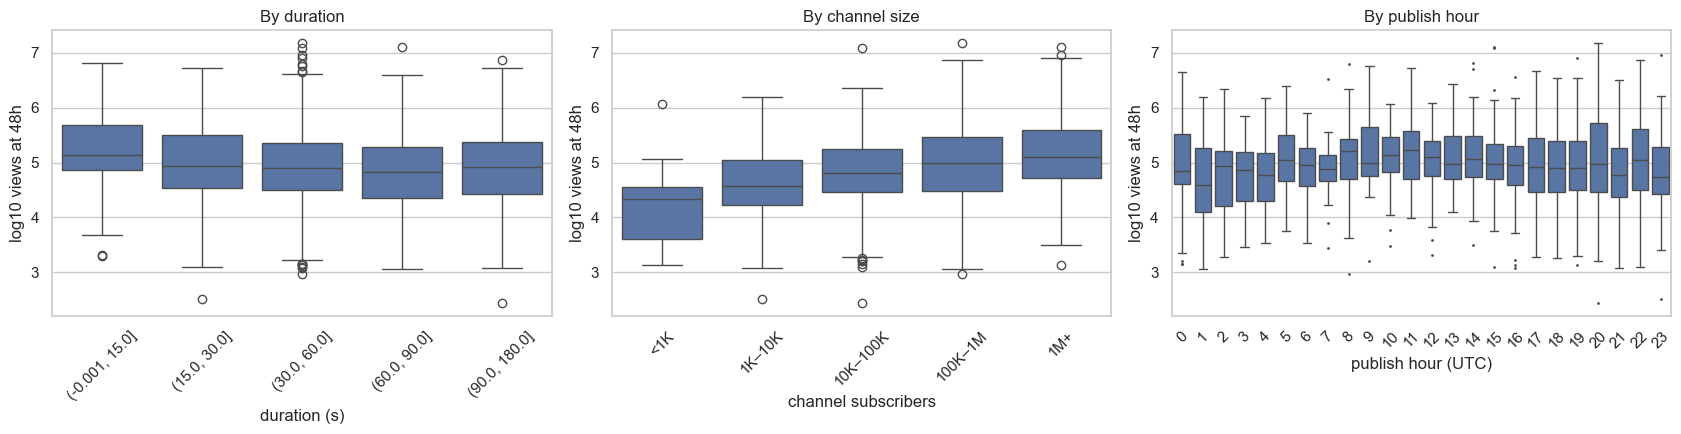

In [15]:
df["log_target"] = np.log10(df[target] + 1)
df["duration_bin"] = pd.cut(df["duration_seconds"], [0, 15, 30, 60, 90, 180], include_lowest=True)
df["subs_bin"] = pd.cut(df["subscriber_count"], [-1, 1e3, 1e4, 1e5, 1e6, np.inf],
                        labels=["<1K", "1K–10K", "10K–100K", "100K–1M", "1M+"])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=df, x="duration_bin", y="log_target", ax=axes[0])
axes[0].set(xlabel="duration (s)", title="By duration")
sns.boxplot(data=df, x="subs_bin", y="log_target", ax=axes[1])
axes[1].set(xlabel="channel subscribers", title="By channel size")
sns.boxplot(data=df, x="pub_hour_utc", y="log_target", ax=axes[2], fliersize=1)
axes[2].set(xlabel="publish hour (UTC)", title="By publish hour")
for ax in axes:
    ax.set_ylabel(f"log10 views at {TARGET_HOURS}h")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
save(fig, "boxplots_by_group")


### Box plots with equal-size bins

The fixed bins above hold very different numbers of videos (a few dozen in some, hundreds in others), so some boxes are much noisier than others. Here each feature is cut at its quantiles instead, so **every box in every panel holds the same number of videos**. Publish time uses time of day to the minute rather than whole hours, so it can be split evenly too. Tick labels show each bin's range and its count. Videos with tied values (e.g. many Shorts are exactly 60s) can be split across neighbouring bins, so adjacent ranges may share an endpoint.

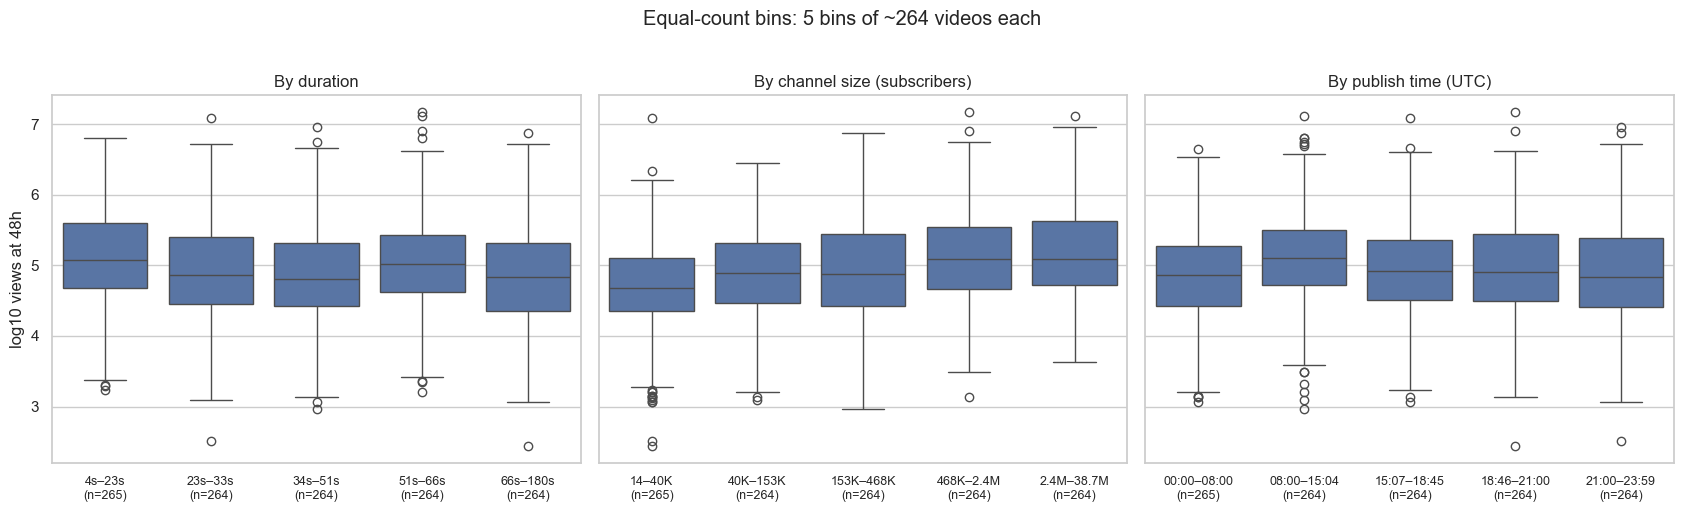

In [16]:
N_BINS = 5

def equal_bins(s, fmt):
    # Split on rank so every bin has the same count (± 1), even with tied values.
    bins = pd.qcut(s.rank(method="first"), N_BINS, labels=False)
    ranges = s.groupby(bins).agg(["min", "max", "size"])
    labels = {b: f"{fmt(r['min'])}–{fmt(r['max'])}\n(n={int(r['size'])})" for b, r in ranges.iterrows()}
    return pd.Categorical(bins.map(labels), categories=[labels[b] for b in sorted(labels)], ordered=True)

def fmt_subs(x):
    return f"{x / 1e6:.1f}M" if x >= 1e6 else f"{x / 1e3:.0f}K" if x >= 1e3 else f"{x:.0f}"

def fmt_time(x):
    return f"{int(x):02d}:{int(round(x % 1 * 60)) % 60:02d}"

df["pub_time_utc"] = df["published_at"].dt.hour + df["published_at"].dt.minute / 60
df["duration_qbin"] = equal_bins(df["duration_seconds"], lambda x: f"{x:.0f}s")
df["subs_qbin"] = equal_bins(df["subscriber_count"], fmt_subs)
df["pub_time_qbin"] = equal_bins(df["pub_time_utc"], fmt_time)

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, (col, title) in zip(axes, [
    ("duration_qbin", "By duration"),
    ("subs_qbin", "By channel size (subscribers)"),
    ("pub_time_qbin", "By publish time (UTC)"),
]):
    sns.boxplot(data=df, x=col, y="log_target", ax=ax)
    ax.set(xlabel="", ylabel=f"log10 views at {TARGET_HOURS}h", title=title)
    ax.tick_params(axis="x", labelsize=9)
fig.suptitle(f"Equal-count bins: {N_BINS} bins of ~{len(df) // N_BINS} videos each", y=1.02)
plt.tight_layout()
save(fig, "boxplots_by_group_equal_bins")


## Correlation heatmap

Spearman (rank) correlation, which is robust to the heavy tails. Look at two things: which features track the target, and which features are near-duplicates of each other (redundancy, per the feature-selection step).

view_count_6h           0.866
view_count_3h           0.784
view_count_1h           0.737
channel_avg_views       0.572
growth_1h_to_6h         0.452
subscriber_count        0.236
n_tags                 -0.162
channel_age_days       -0.152
total_channel_videos   -0.135
comment_rate_6h        -0.133
title_len              -0.126
like_rate_6h           -0.083
duration_seconds       -0.082
n_hashtags             -0.036
pub_hour_utc           -0.015
Name: view_count_48h, dtype: float64

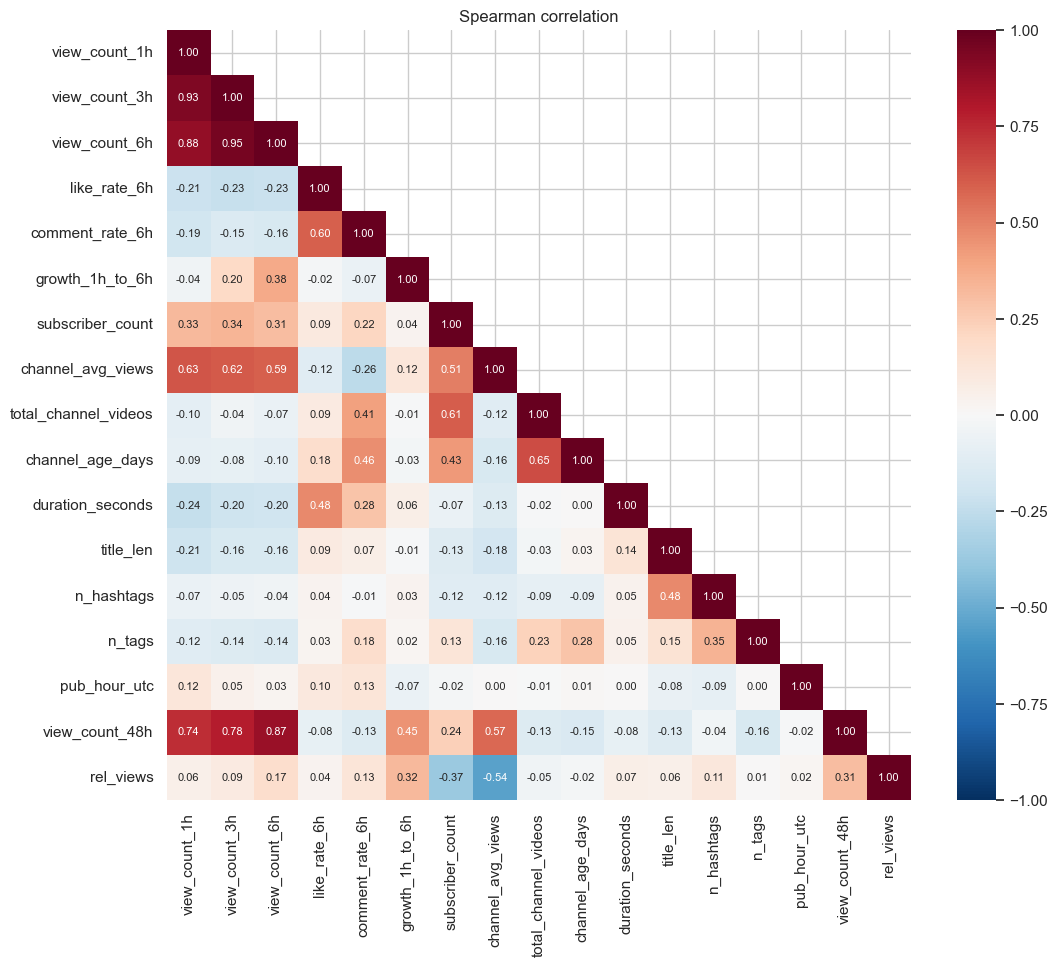

In [17]:
corr_cols = ["view_count_1h", "view_count_3h", "view_count_6h", "like_rate_6h", "comment_rate_6h",
             "growth_1h_to_6h", "subscriber_count", "channel_avg_views", "total_channel_videos",
             "channel_age_days", "duration_seconds", "title_len", "n_hashtags", "n_tags",
             "pub_hour_utc", target, "rel_views"]
corr = df[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 8}, ax=ax)
ax.set_title("Spearman correlation")
save(fig, "correlation_heatmap")

corr[target].drop([target, "rel_views"]).sort_values(key=abs, ascending=False).round(3)


## How well do early views predict the outcome?

This is the core of "can we predict it early?" Each panel plots views at hour N against views at the target age.

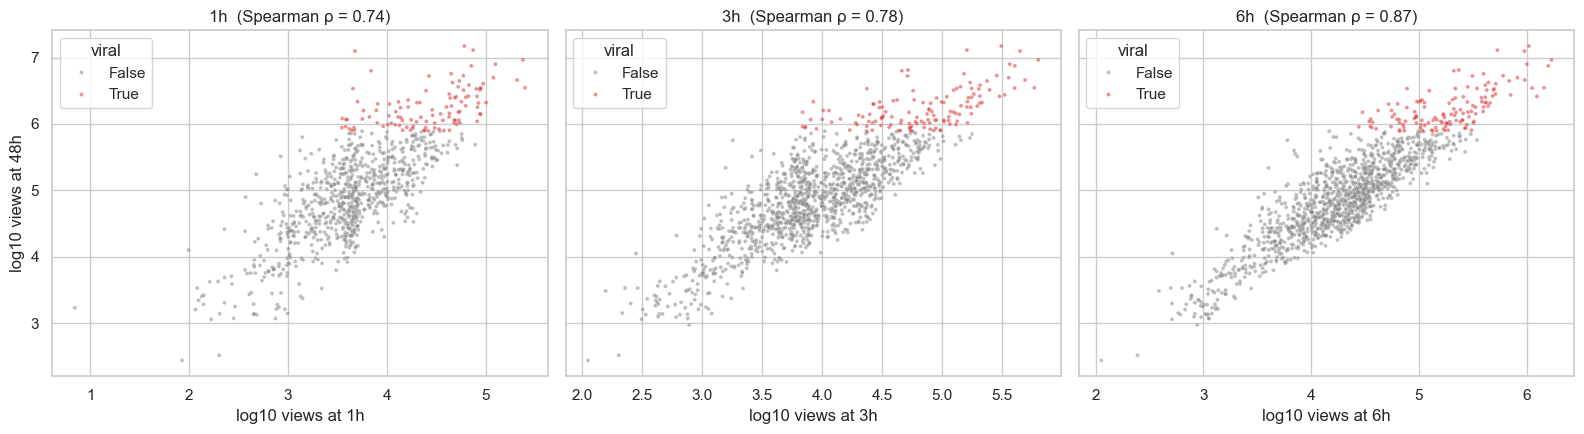

In [18]:
fig, axes = plt.subplots(1, len(EARLY_HOURS), figsize=(16, 4.5), sharey=True)
for ax, h in zip(axes, EARLY_HOURS):
    d = df.dropna(subset=[f"view_count_{h}h"])
    sns.scatterplot(x=np.log10(d[f"view_count_{h}h"] + 1), y=d["log_target"], hue=d["viral"],
                    s=8, alpha=0.5, ax=ax, palette={False: "tab:gray", True: "tab:red"})
    rho = d[f"view_count_{h}h"].corr(d[target], method="spearman")
    ax.set(xlabel=f"log10 views at {h}h", ylabel=f"log10 views at {TARGET_HOURS}h", title=f"{h}h  (Spearman ρ = {rho:.2f})")
plt.tight_layout()
save(fig, "early_vs_target_views")


## Growth curves: viral vs. non-viral

Median views by age, with the interquartile range shaded. Where the two bands separate is roughly how early the signal appears.

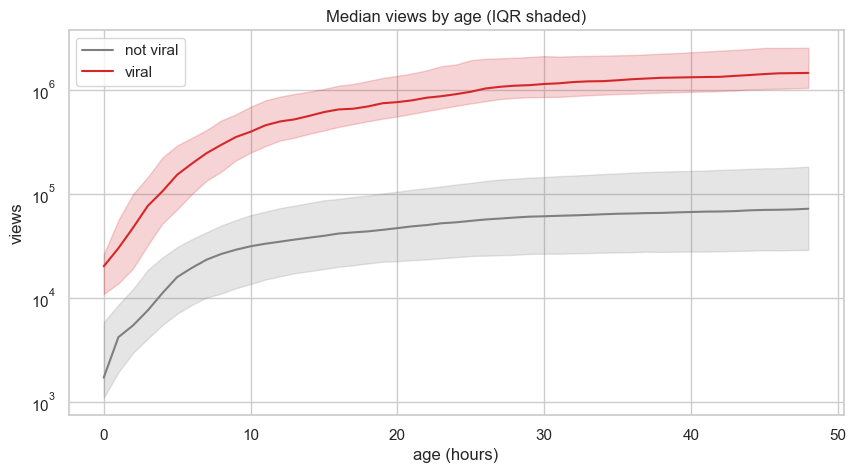

In [19]:
curves = observations.merge(df[["video_id", "viral"]], on="video_id")
curves["age_bin"] = curves["age_hours"].round()
curves = curves[curves["age_bin"] <= TARGET_HOURS]
summary = curves.groupby(["viral", "age_bin"])["view_count"].quantile([0.25, 0.5, 0.75]).unstack()

fig, ax = plt.subplots(figsize=(10, 5))
for is_viral, color in [(False, "tab:gray"), (True, "tab:red")]:
    s = summary.loc[is_viral]
    ax.plot(s.index, s[0.5], color=color, label="viral" if is_viral else "not viral")
    ax.fill_between(s.index, s[0.25], s[0.75], color=color, alpha=0.2)
ax.set(yscale="log", xlabel="age (hours)", ylabel="views", title="Median views by age (IQR shaded)")
ax.legend()
save(fig, "growth_curves_viral_vs_not")


## Splitting videos by virality: top 10% vs. bottom 90%

Videos in the modeling table are split on views at `TARGET_HOURS`: the top 10% (`viral`) against everyone else. Then every snapshot of each video gets its group, so we can follow the two groups over time.

In [20]:
top10 = df[df["viral"]]
bottom90 = df[~df["viral"]]
print(f"top 10%:    {len(top10):>5} videos, {top10[target].min():>12,.0f} – {top10[target].max():,.0f} views at {TARGET_HOURS}h")
print(f"bottom 90%: {len(bottom90):>5} videos, {bottom90[target].min():>12,.0f} – {bottom90[target].max():,.0f} views at {TARGET_HOURS}h")

GROUP_COLORS = {"top 10%": "tab:red", "bottom 90%": "tab:gray"}

traj = (
    observations.merge(df[["video_id", "viral", target]], on="video_id")
    .sort_values(["video_id", "age_hours"])
)
traj["group"] = np.where(traj["viral"], "top 10%", "bottom 90%")
# Views per hour since the previous snapshot (or since publish, for the first snapshot)
traj["velocity"] = (
    traj.groupby("video_id")["view_count"].diff().fillna(traj["view_count"])
    / traj.groupby("video_id")["age_hours"].diff().fillna(traj["age_hours"])
).clip(lower=0)
traj["like_rate"] = traj["like_count"] / traj["view_count"].replace(0, np.nan)
traj["comment_rate"] = traj["comment_count"] / traj["view_count"].replace(0, np.nan)
traj["share_of_target"] = traj["view_count"] / traj[target].replace(0, np.nan)
traj["age_bin"] = traj["age_hours"].round()
traj = traj[traj["age_bin"] <= TARGET_HOURS]

def plot_bands(ax, col, log=True):
    # Median by hour of age for each group, with the interquartile range shaded.
    q = traj.groupby(["group", "age_bin"])[col].quantile([0.25, 0.5, 0.75]).unstack()
    for group, color in GROUP_COLORS.items():
        s = q.loc[group]
        ax.plot(s.index, s[0.5], color=color, label=group)
        ax.fill_between(s.index, s[0.25], s[0.75], color=color, alpha=0.2)
    ax.set(xlabel="age (hours)", yscale="log" if log else "linear")
    ax.legend()


top 10%:      133 videos,      779,085 – 14,912,670 views at 48h
bottom 90%:  1188 videos,          272 – 777,984 views at 48h


### Engagement over time

Median by hour of age, IQR shaded. Velocity shows *when* views arrive: whether viral videos take off early or keep a higher pace for longer. Like and comment rates show whether viral videos are also more engaging per view, or just seen more.

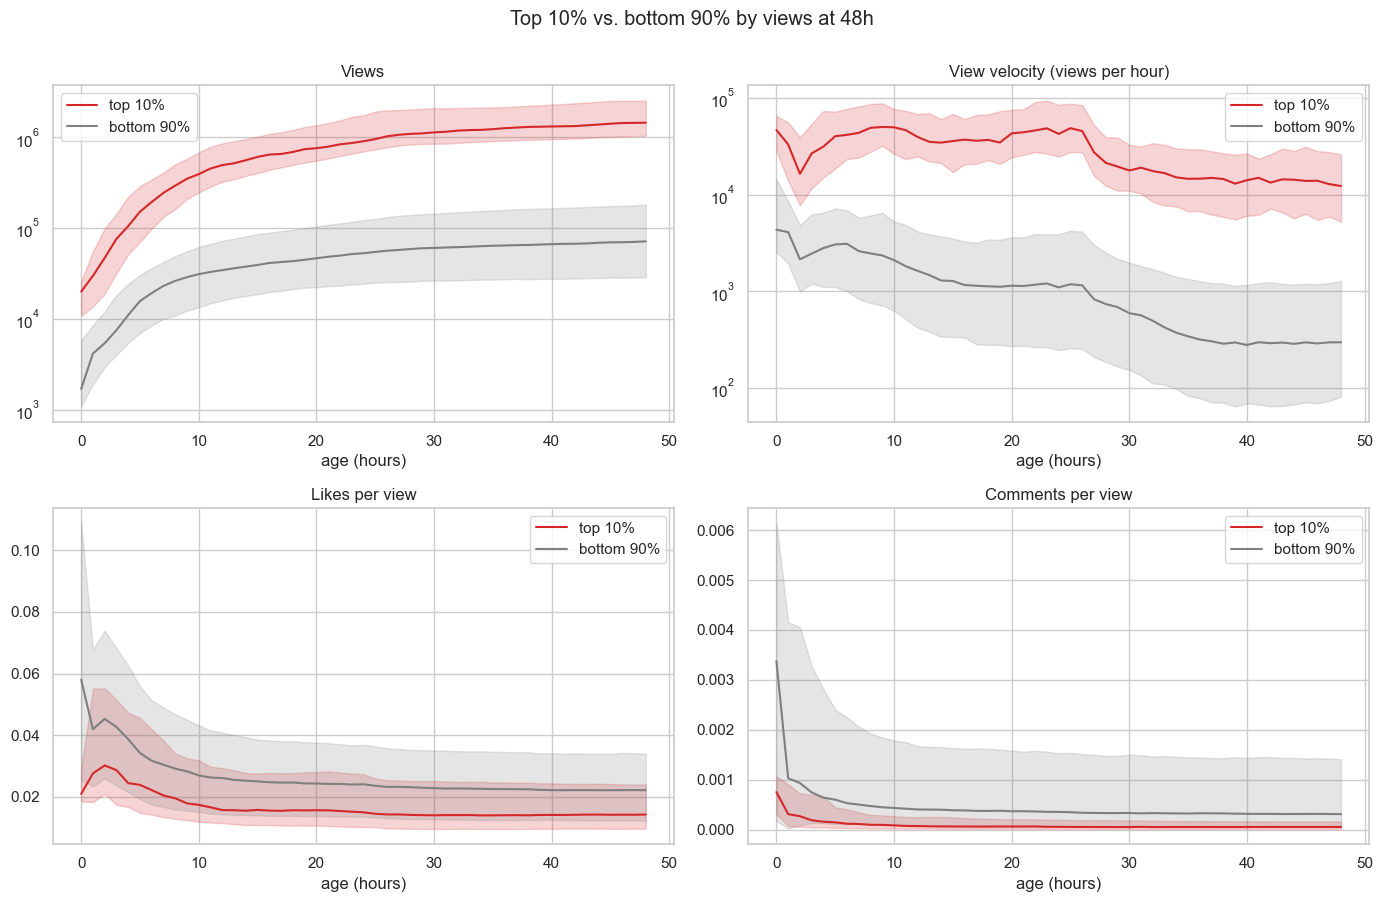

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (col, title, log) in zip(axes.flat, [
    ("view_count", "Views", True),
    ("velocity", "View velocity (views per hour)", True),
    ("like_rate", "Likes per view", False),
    ("comment_rate", "Comments per view", False),
]):
    plot_bands(ax, col, log)
    ax.set_title(title)
fig.suptitle(f"Top 10% vs. bottom 90% by views at {TARGET_HOURS}h", y=1.0)
plt.tight_layout()
save(fig, "virality_groups_over_time")


### Individual trajectories

Medians hide how varied the videos are. Each thin line is one video (25 sampled per group), with the group median in bold.

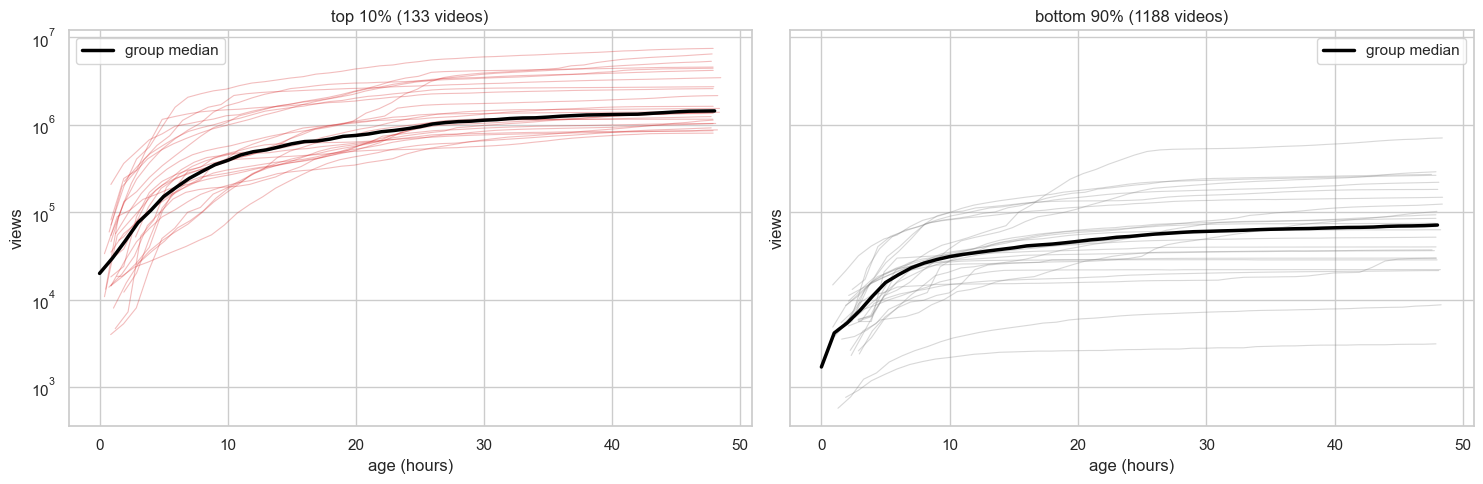

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
median_views = traj.groupby(["group", "age_bin"])["view_count"].median()
for ax, (group, color) in zip(axes, GROUP_COLORS.items()):
    g = traj[traj["group"] == group]
    ids = g["video_id"].drop_duplicates().sample(min(25, g["video_id"].nunique()), random_state=0)
    for _, v in g[g["video_id"].isin(ids)].groupby("video_id"):
        ax.plot(v["age_hours"], v["view_count"], color=color, alpha=0.3, lw=0.8)
    ax.plot(median_views.loc[group], color="black", lw=2.5, label="group median")
    ax.set(yscale="log", xlabel="age (hours)", ylabel="views", title=f"{group} ({g['video_id'].nunique()} videos)")
    ax.legend()
plt.tight_layout()
save(fig, "virality_groups_trajectories")


### How front-loaded is each group?

Each video's views as a fraction of its own views at `TARGET_HOURS`. A curve that reaches 1 quickly means a video got most of its views early and then stalled; a slow climb means it kept growing.

median share of 48h views reached by  1h: top 10% 2%, bottom 90% 6%
median share of 48h views reached by  3h: top 10% 5%, bottom 90% 13%
median share of 48h views reached by  6h: top 10% 13%, bottom 90% 29%
median share of 48h views reached by 24h: top 10% 68%, bottom 90% 79%


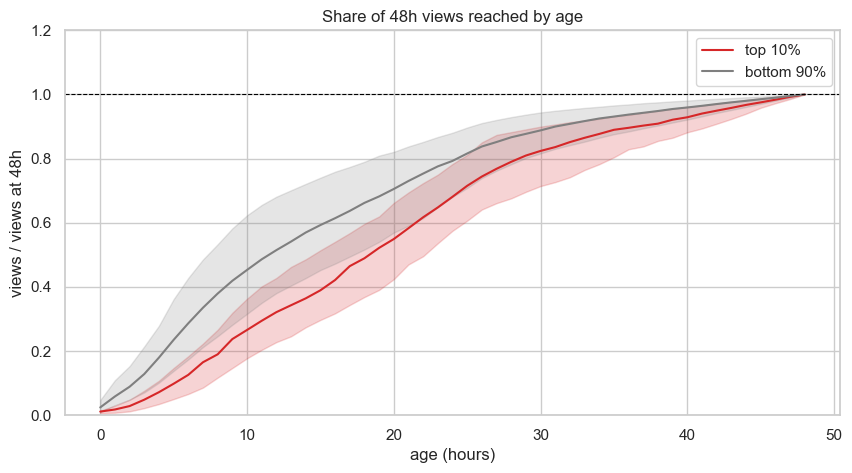

In [23]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_bands(ax, "share_of_target", log=False)
ax.axhline(1, color="black", lw=0.8, ls="--")
ax.set(ylabel=f"views / views at {TARGET_HOURS}h", title=f"Share of {TARGET_HOURS}h views reached by age", ylim=(0, 1.2))
save(fig, "virality_groups_share_of_target")

for h in EARLY_HOURS + [24]:
    shares = traj[traj["age_bin"] == h].groupby("group")["share_of_target"].median()
    print(f"median share of {TARGET_HOURS}h views reached by {h:>2}h: "
          + ", ".join(f"{g} {shares.get(g, np.nan):.0%}" for g in GROUP_COLORS))


## Tags: viral vs. non-viral

Creators can attach tags to a video. Here each video's tags are cleaned (lowercased, `#` removed, strings like `"#minecraft #fyp"` split into separate tags, and each tag counted once per video), then counted separately for viral (top 10%) and non-viral (bottom 90%) videos.

Caveats:
- Many videos have no tags at all, so these counts come from a minority of videos.
- One channel can put the same tags on many of its videos, so a tag's count may reflect a single prolific channel rather than a trend. The plots show how many channels used each tag.

In [24]:
def clean_tags(raw):
    # Lowercase, drop '#', split multi-hashtag strings, and de-duplicate a video's tags.
    tags = set()
    for t in json.loads(raw) if isinstance(raw, str) else []:
        parts = t.split() if t.count("#") > 1 else [t]
        tags.update(p.strip().lstrip("#").strip().lower() for p in parts)
    return sorted(tags - {""})

def count_tags(tag_lists, kind="tags"):
    # One row per tag: how many viral / non-viral videos (and channels) use it.
    # `tag_lists` is a Series aligned with df holding each video's list of tags.
    n_videos = df["viral"].value_counts()
    has_any = tag_lists.str.len() > 0
    for flag, name in [(True, "viral"), (False, "non-viral")]:
        n_has = has_any[df["viral"] == flag].sum()
        print(f"{name:>9}: {n_has:>4} of {n_videos[flag]:>4} videos have {kind} ({n_has / n_videos[flag]:.0%})")

    long = (
        df[["video_id", "channel_id", "viral"]].assign(tag=tag_lists)
        .explode("tag").dropna(subset=["tag"])
    )
    counts = (
        long.groupby(["tag", "viral"])
        .agg(videos=("video_id", "size"), channels=("channel_id", "nunique"))
        .unstack("viral", fill_value=0)
    )
    counts.columns = [f"{'viral' if v else 'nonviral'}_{stat}" for stat, v in counts.columns]
    counts["channels"] = long.groupby("tag")["channel_id"].nunique()
    # Share of each group's videos using the tag, so the two groups (different sizes) are comparable
    counts["pct_viral"] = 100 * counts["viral_videos"] / n_videos[True]
    counts["pct_nonviral"] = 100 * counts["nonviral_videos"] / n_videos[False]
    counts["pct_diff"] = counts["pct_viral"] - counts["pct_nonviral"]
    print(f"\n{len(counts)} distinct {kind}")
    return counts

df["tag_list"] = df["tags"].apply(clean_tags)
tag_counts = count_tags(df["tag_list"], "tags")
tag_counts.sort_values("viral_videos", ascending=False).head(10)


    viral:   32 of  133 videos have tags (24%)
non-viral:  468 of 1188 videos have tags (39%)

4719 distinct tags


,nonviral_videos,viral_videos,nonviral_channels,viral_channels,channels,pct_viral,pct_nonviral,pct_diff
tag,,,,,,,,
minecraft,31,10,17,4,19,7.518797,2.609428,4.909369
shorts,188,9,116,9,120,6.766917,15.824916,-9.057999
trending,19,8,12,4,13,6.015038,1.599327,4.415711
fyp,15,7,9,3,10,5.263158,1.262626,4.000532
kids,8,5,3,1,3,3.759398,0.673401,3.085998
popular,5,5,1,1,1,3.759398,0.420875,3.338523
minecraft shorts,13,4,9,2,10,3.007519,1.094276,1.913243
memes,7,3,5,1,6,2.255639,0.589226,1.666414
minecraft memes,2,3,2,1,3,2.255639,0.168350,2.087289


### Most common tags in each group

Bar length is the number of videos in that group using the tag; the label gives the number of distinct channels behind those videos.

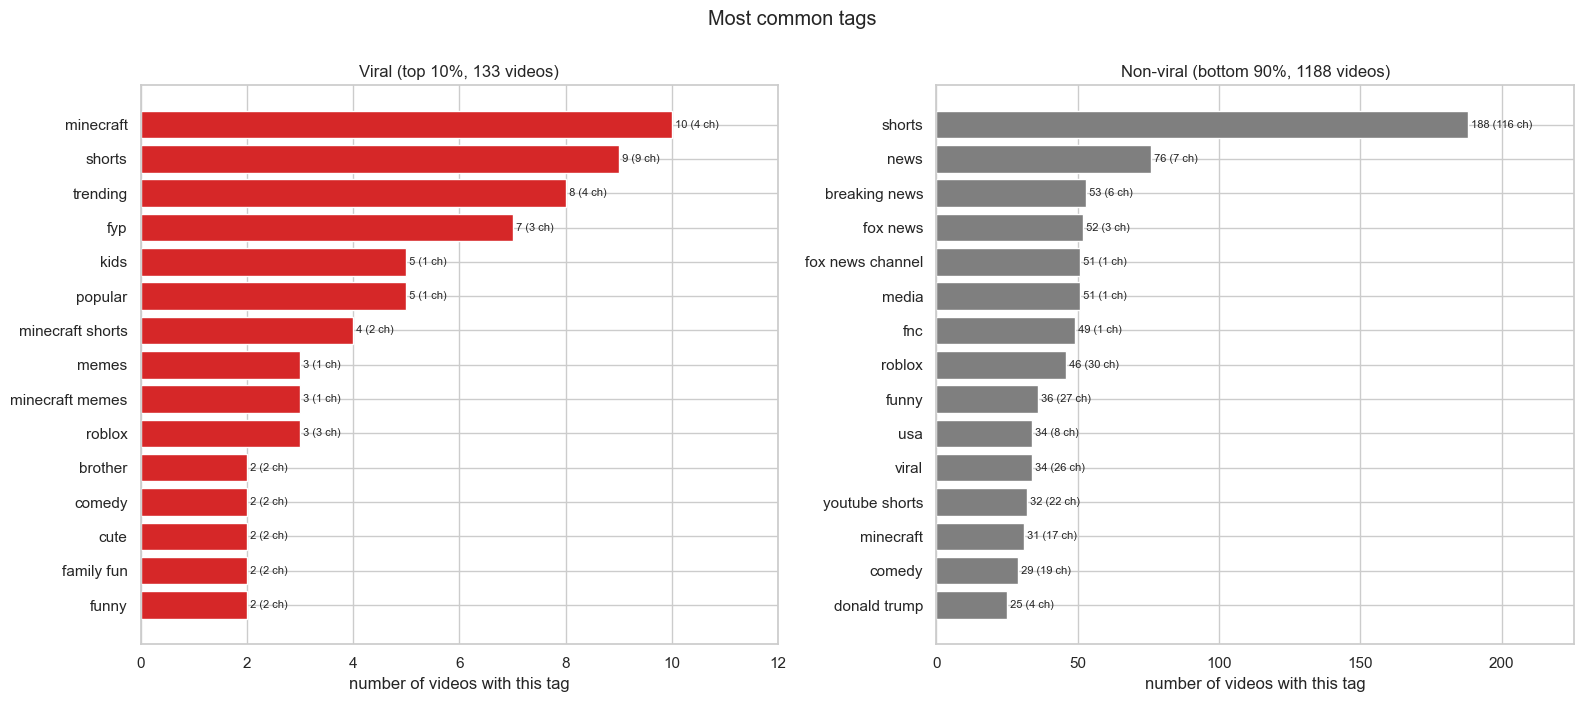

In [25]:
TOP_N_TAGS = 15

def short(tag, n=35):
    return tag if len(tag) <= n else tag[:n - 1] + "…"

def plot_most_common(counts, kind="tags", name="tags"):
    n_videos = df["viral"].value_counts()
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    for ax, (prefix, title, color) in zip(axes, [
        ("viral", f"Viral (top 10%, {n_videos[True]} videos)", GROUP_COLORS["top 10%"]),
        ("nonviral", f"Non-viral (bottom 90%, {n_videos[False]} videos)", GROUP_COLORS["bottom 90%"]),
    ]):
        top = counts.nlargest(TOP_N_TAGS, f"{prefix}_videos").iloc[::-1]
        ax.barh([short(t) for t in top.index], top[f"{prefix}_videos"], color=color)
        for y, (n, ch) in enumerate(zip(top[f"{prefix}_videos"], top[f"{prefix}_channels"])):
            ax.text(n, y, f" {n} ({ch} ch)", va="center", fontsize=8)
        ax.set(xlabel=f"number of videos with this {kind.rstrip('s')}", title=title)
        ax.margins(x=0.2)
    fig.suptitle(f"Most common {kind}", y=1.0)
    plt.tight_layout()
    save(fig, f"{name}_most_common_by_group")

plot_most_common(tag_counts, "tags", "tags")


### Tags that most separate viral from non-viral videos

Difference in the share of videos using each tag: % of viral videos minus % of non-viral videos. Red bars are tags more common among viral videos; gray bars are more common among non-viral ones. Labels give each group's percentage and how many channels it comes from. Only tags used by at least `MIN_TAG_CHANNELS` different channels are included, so one channel tagging many of its own videos can't dominate.

With this few tagged viral videos, a tag on a handful of viral videos is enough to rank high. Treat this as a list of leads, not evidence.

,viral_videos,nonviral_videos,viral_channels,nonviral_channels,pct_viral,pct_nonviral,pct_diff
tag,,,,,,,
shorts,9,188,9,116,6.77,15.82,-9.06
news,1,76,1,7,0.75,6.40,-5.65
breaking news,0,53,0,6,0.00,4.46,-4.46
fox news,1,52,1,3,0.75,4.38,-3.63
youtube shorts,0,32,0,22,0.00,2.69,-2.69
usa,1,34,1,8,0.75,2.86,-2.11
us news,0,25,0,4,0.00,2.10,-2.10
donald trump,0,25,0,4,0.00,2.10,-2.10
roblox,3,46,3,30,2.26,3.87,-1.62


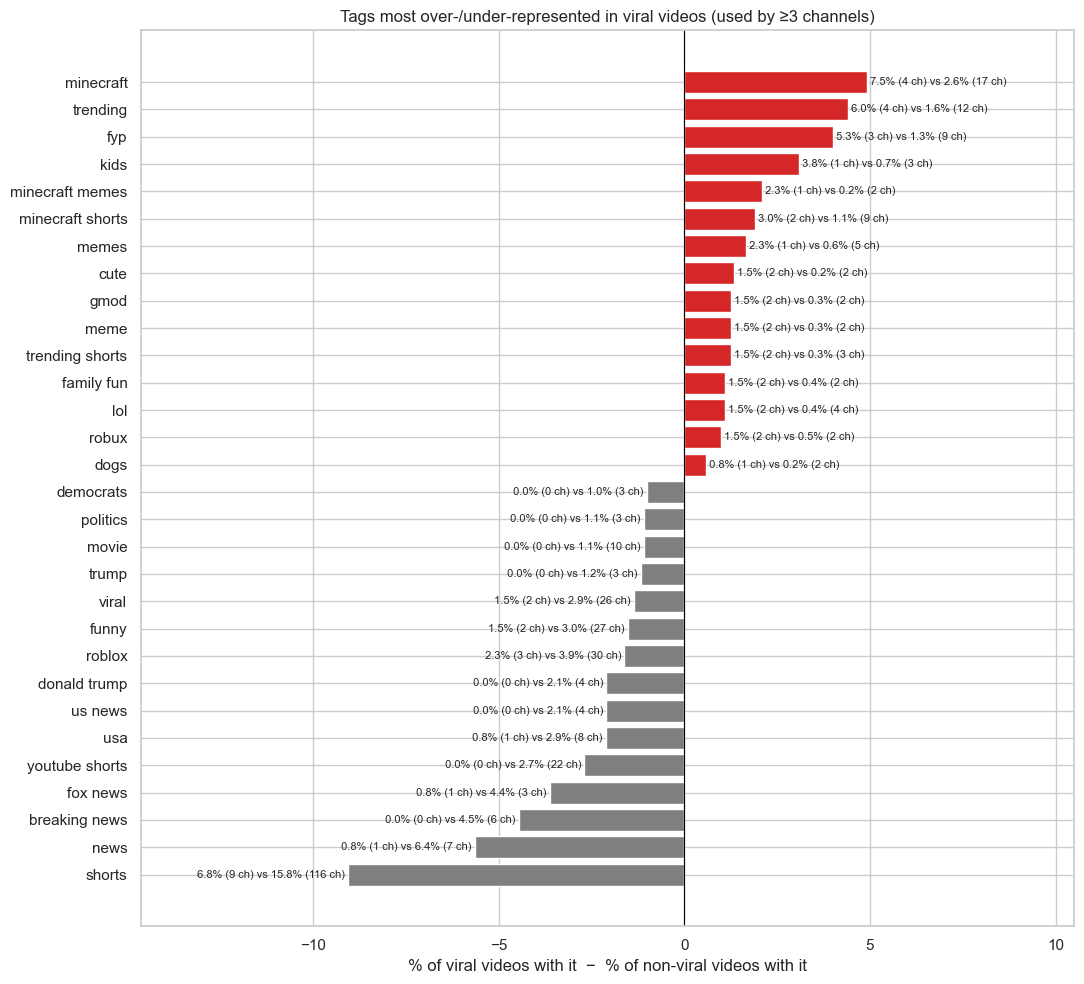

In [26]:
MIN_TAG_CHANNELS = 3

def plot_tag_difference(counts, kind="tags", name="tags"):
    eligible = counts[counts["channels"] >= MIN_TAG_CHANNELS]
    diff = pd.concat([
        eligible.nlargest(TOP_N_TAGS, "pct_diff").query("pct_diff > 0"),
        eligible.nsmallest(TOP_N_TAGS, "pct_diff").query("pct_diff < 0"),
    ]).sort_values("pct_diff")

    fig, ax = plt.subplots(figsize=(11, 10))
    colors = np.where(diff["pct_diff"] > 0, GROUP_COLORS["top 10%"], GROUP_COLORS["bottom 90%"])
    ax.barh([short(t) for t in diff.index], diff["pct_diff"], color=colors)
    for y, (d, r) in enumerate(diff.iterrows()):
        label = f" {r['pct_viral']:.1f}% ({r['viral_channels']:.0f} ch) vs {r['pct_nonviral']:.1f}% ({r['nonviral_channels']:.0f} ch) "
        ax.text(r["pct_diff"], y, label, va="center", ha="left" if r["pct_diff"] > 0 else "right", fontsize=8)
    ax.axvline(0, color="black", lw=0.8)
    ax.set(xlabel=f"% of viral videos with it  −  % of non-viral videos with it",
           title=f"{kind.capitalize()} most over-/under-represented in viral videos (used by ≥{MIN_TAG_CHANNELS} channels)")
    ax.margins(x=0.4)
    plt.tight_layout()
    save(fig, f"{name}_viral_vs_nonviral_difference")
    return diff[["viral_videos", "nonviral_videos", "viral_channels", "nonviral_channels",
                 "pct_viral", "pct_nonviral", "pct_diff"]].round(2)

plot_tag_difference(tag_counts, "tags", "tags")


## Description hashtags: viral vs. non-viral

Many creators put hashtags in the video description instead of (or as well as) the tag field, and descriptions are far more often filled in than tags. Same analysis as the tag section: hashtags are pulled out of each description with a regex, lowercased, and counted once per video. Same caveats too: only part of the videos have any, and one channel reusing the same hashtags can inflate a count.

In [27]:
HASHTAG_RE = re.compile(r"#(\w+)")

def extract_hashtags(text):
    return sorted({h.lower() for h in HASHTAG_RE.findall(text)}) if isinstance(text, str) else []

df["desc_hashtags"] = df["description"].apply(extract_hashtags)
has_tags, has_hashtags = df["tag_list"].str.len() > 0, df["desc_hashtags"].str.len() > 0
print(f"tags only: {(has_tags & ~has_hashtags).sum()}, description hashtags only: {(has_hashtags & ~has_tags).sum()}, "
      f"both: {(has_tags & has_hashtags).sum()}, neither: {(~has_tags & ~has_hashtags).sum()}\n")

hashtag_counts = count_tags(df["desc_hashtags"], "description hashtags")
hashtag_counts.sort_values("viral_videos", ascending=False).head(10)


tags only: 135, description hashtags only: 233, both: 365, neither: 588

    viral:   44 of  133 videos have description hashtags (33%)
non-viral:  554 of 1188 videos have description hashtags (47%)

1659 distinct description hashtags


,nonviral_videos,viral_videos,nonviral_channels,viral_channels,channels,pct_viral,pct_nonviral,pct_diff
tag,,,,,,,,
shorts,348,31,242,25,253,23.308271,29.292929,-5.984659
minecraft,36,10,23,5,25,7.518797,3.030303,4.488494
funny,44,8,29,8,32,6.015038,3.703704,2.311334
roblox,55,6,39,5,41,4.511278,4.629630,-0.118351
viral,49,6,38,5,39,4.511278,4.124579,0.386699
fyp,15,4,13,4,14,3.007519,1.262626,1.744893
jj,4,3,2,1,2,2.255639,0.336700,1.918939
usa,32,3,13,3,14,2.255639,2.693603,-0.437964
youtubeshorts,29,3,20,3,21,2.255639,2.441077,-0.185438


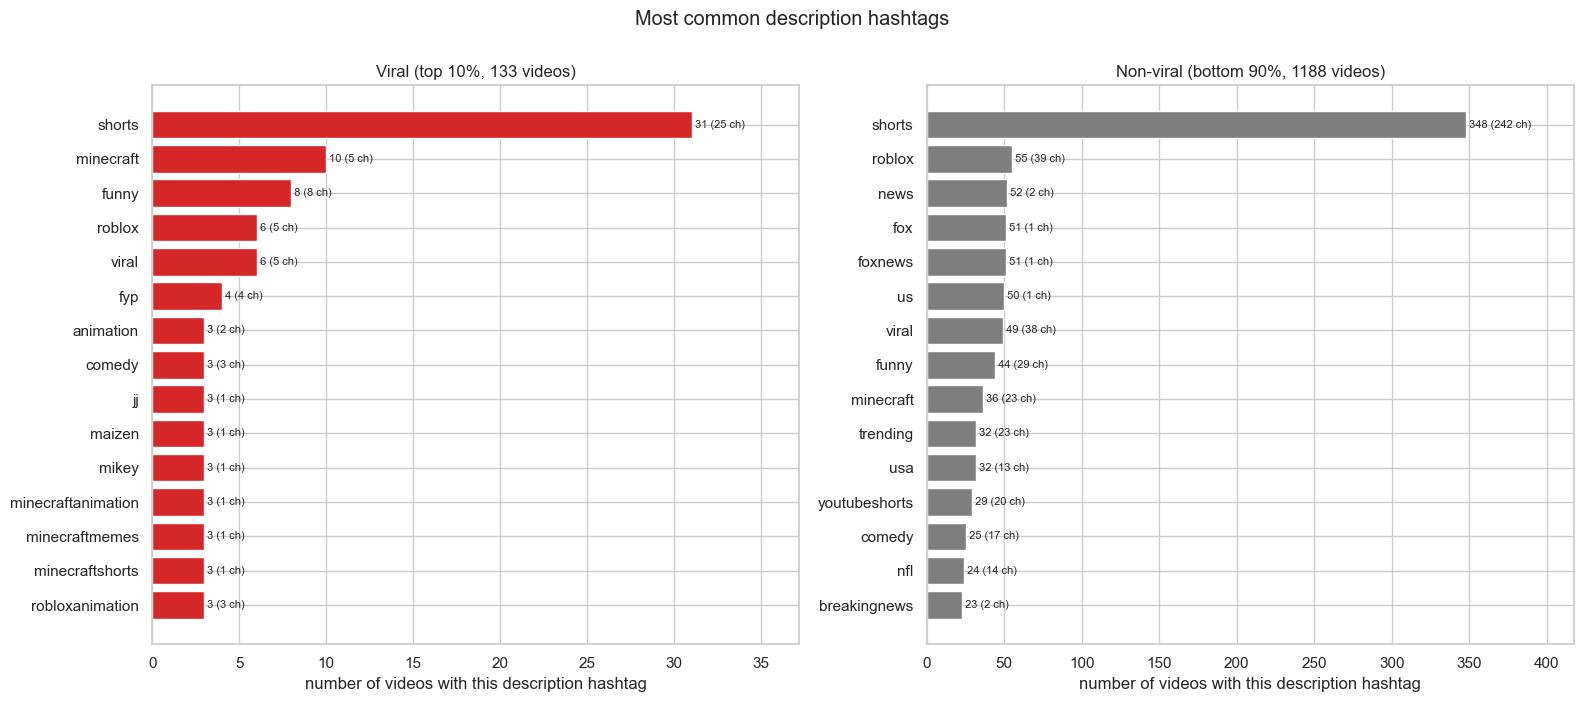

In [28]:
plot_most_common(hashtag_counts, "description hashtags", "desc_hashtags")


,viral_videos,nonviral_videos,viral_channels,nonviral_channels,pct_viral,pct_nonviral,pct_diff
tag,,,,,,,
shorts,31,348,25,242,23.31,29.29,-5.98
nfl,0,24,0,14,0.00,2.02,-2.02
new,0,22,0,4,0.00,1.85,-1.85
gaming,0,21,0,17,0.00,1.77,-1.77
trump,0,17,0,3,0.00,1.43,-1.43
trending,2,32,2,23,1.50,2.69,-1.19
football,0,13,0,11,0.00,1.09,-1.09
robloxedit,0,12,0,6,0.00,1.01,-1.01
shortvideo,1,20,1,9,0.75,1.68,-0.93


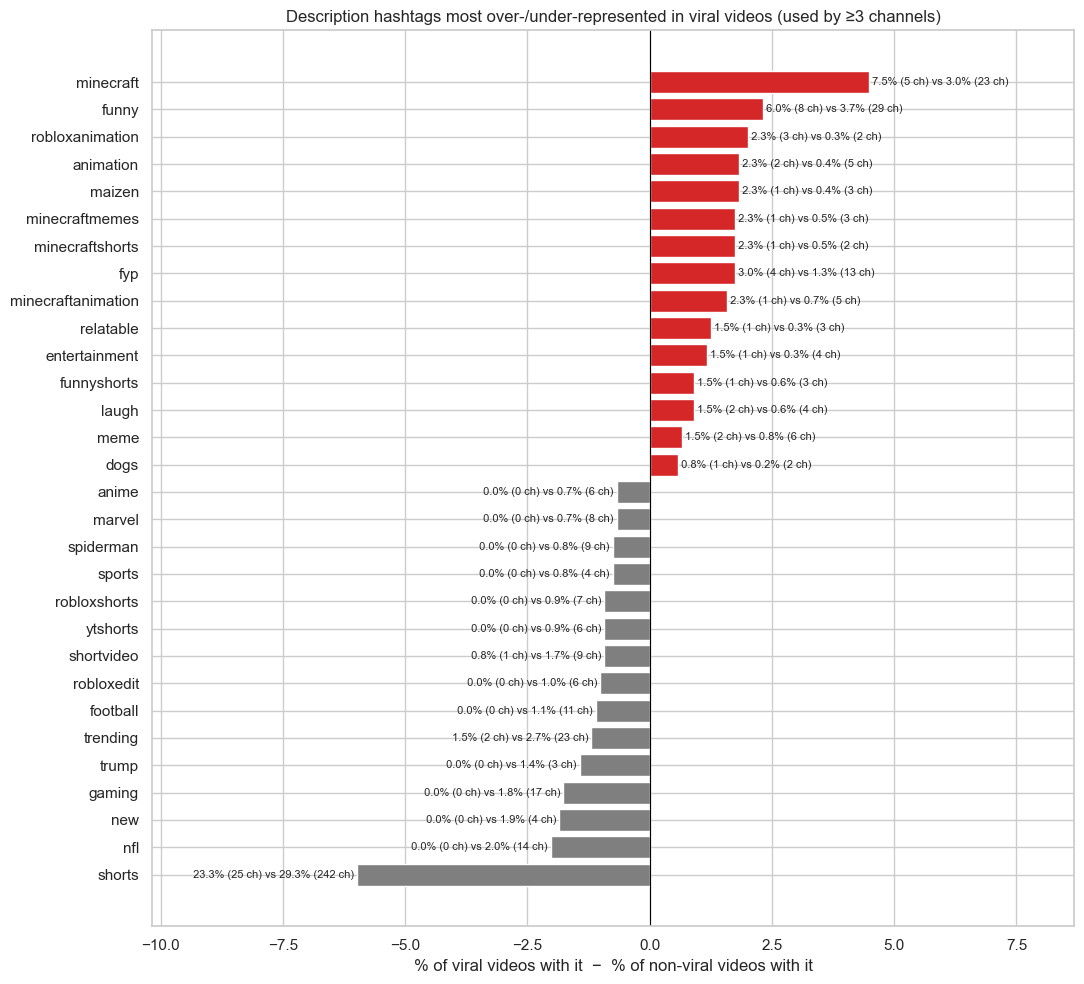

In [29]:
plot_tag_difference(hashtag_counts, "description hashtags", "desc_hashtags")


## Two definitions of viral: how much do they agree?

In [30]:
print(pd.crosstab(df["viral"], df["viral_rel"], margins=True))
both = (df["viral"] & df["viral_rel"]).sum()
print(f"\nJaccard overlap: {both / (df['viral'] | df['viral_rel']).sum():.2f}")
print("\nmedian subscribers by label:")
print(df.groupby(["viral", "viral_rel"])["subscriber_count"].median().map("{:,.0f}".format))


viral_rel  False  True   All
viral                       
False       1087   101  1188
True         101    32   133
All         1188   133  1321

Jaccard overlap: 0.14

median subscribers by label:
viral  viral_rel
False  False        253,000
       True          28,200
True   False        828,000
       True         186,000
Name: subscriber_count, dtype: object


## Outliers and data quality

- **Z-scores** on log views flag extreme videos.
- **Isolation Forest** flags unusual combinations of features, not just extreme values in one feature.
- **View counts that go down** between snapshots: YouTube sometimes removes invalid views, so counts aren't strictly increasing.

In [31]:
from sklearn.ensemble import IsolationForest

df["target_z"] = stats.zscore(df["log_target"])
print(f"|z| > 3 on log views: {(df['target_z'].abs() > 3).sum()} videos")

iso_cols = ["view_count_6h", "subscriber_count", "channel_avg_views", "duration_seconds"]
iso_X = np.log10(df[iso_cols].dropna() + 1)
df["iso_outlier"] = False
df.loc[iso_X.index, "iso_outlier"] = IsolationForest(contamination=0.02, random_state=0).fit_predict(iso_X) == -1
print(f"IsolationForest outliers: {df['iso_outlier'].sum()} videos")
display(df.loc[df["iso_outlier"], ["title", "channel_title", "subscriber_count", "view_count_6h", target]].head(10))

o = observations.sort_values(["video_id", "observed_at"])
drops = o.groupby("video_id")["view_count"].diff()
print(f"\nsnapshots where views went down: {(drops < 0).sum()} across {o.loc[drops < 0, 'video_id'].nunique()} videos")
print("size of drop as a fraction of views:")
print((drops[drops < 0] / o.loc[drops < 0, "view_count"]).describe().round(4))


|z| > 3 on log views: 3 videos
IsolationForest outliers: 27 videos


,title,channel_title,subscriber_count,view_count_6h,view_count_48h
77,Scary Office Halloween Decorations: Workplace ...,New Country 105.1 KNCI,2190,1130.0,1175.0
95,West Virginia's Fight for Freedom: Slavery's E...,Truth & Liberty,26300,584.0,1415.0
199,The Best NFL Survivor Pool Pick for Week 6! #s...,BettingPros,81700,695.0,1914.0
205,Which Baby Is It? 👶🍔🍕 Guess the Baby Challenge...,GOLDCRAFT STUDIOS,11500000,422590.0,2095044.0
220,Genius idea using bottles that were going to t...,Vintage Valor,2880,1452.0,5178.0
223,How to survive Wolf Mama: Blueberries 2 | Fami...,ezez game,57100,272759.0,876209.0
227,"Every Night at Midnight, TOYS Go to Work... #s...",BrooXi,1870,30411.0,48855.0
300,Which Baby Is It? 👶🐝 #shorts,GOLDCRAFT STUDIOS,11500000,413905.0,2524398.0
324,🌱 Dirty Gardening Hands? Wash Before You Eat! ...,Little Together,597,386.0,3039.0
455,Inherit Pringles for Life or Cash: Weirdest Fa...,New Country 105.1 KNCI,2190,244.0,326.0



snapshots where views went down: 1085 across 423 videos
size of drop as a fraction of views:
count    1085.0000
mean       -0.0018
std         0.0061
min        -0.1381
25%        -0.0015
50%        -0.0005
75%        -0.0001
max        -0.0000
Name: view_count, dtype: float64


## Lag structure: view velocity over time

Velocity = new views per hour between consecutive snapshots. If velocity is strongly autocorrelated, a video's recent pace is a good guide to its next few hours, which is what makes early prediction plausible.

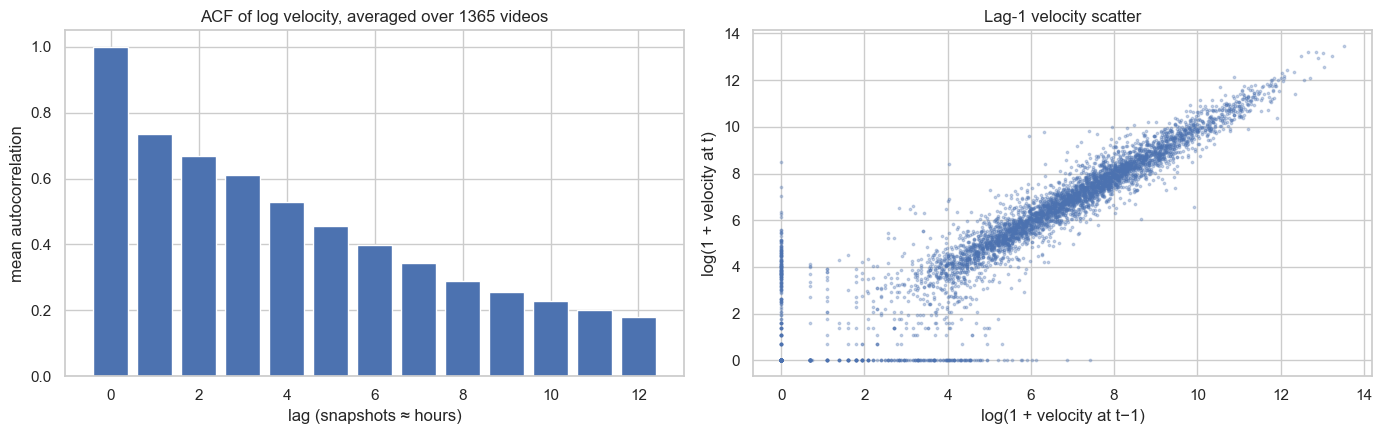

In [32]:
o = observations.sort_values(["video_id", "age_hours"]).copy()
o["velocity"] = (o.groupby("video_id")["view_count"].diff() / o.groupby("video_id")["age_hours"].diff()).clip(lower=0)
o["velocity_lag1"] = o.groupby("video_id")["velocity"].shift()

# Average the per-video ACF over videos with long histories
long_ids = o.groupby("video_id")["velocity"].count().loc[lambda s: s >= 36].index
acfs = np.array([acf(np.log1p(g["velocity"].dropna()), nlags=12)
                 for _, g in o[o["video_id"].isin(long_ids)].groupby("video_id")])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(range(13), np.nanmean(acfs, axis=0))
axes[0].set(xlabel="lag (snapshots ≈ hours)", ylabel="mean autocorrelation",
            title=f"ACF of log velocity, averaged over {len(acfs)} videos")
sample = o.dropna(subset=["velocity", "velocity_lag1"]).sample(5000, random_state=0)
axes[1].scatter(np.log1p(sample["velocity_lag1"]), np.log1p(sample["velocity"]), s=3, alpha=0.3)
axes[1].set(xlabel="log(1 + velocity at t−1)", ylabel="log(1 + velocity at t)", title="Lag-1 velocity scatter")
plt.tight_layout()
save(fig, "velocity_acf")
